# Avance 3 — Proyecto Integrador: Aprendizaje No Supervisado (FinanceGuard)

En los avances anteriores abordamos la fuga de clientes (*churn*) como un problema **supervisado**: entrenamos modelos que usaban la etiqueta `Exited` para predecir quién iba a abandonar el banco.

En este tercer avance cambiamos de enfoque y aplicamos **Aprendizaje No Supervisado**: ocultamos la variable objetivo `Exited` durante el entrenamiento para descubrir si existen **segmentos naturales de clientes** en la cartera de FinanceGuard y recién al final evaluamos qué tasa de abandono presenta cada grupo.

**Hoja de ruta del notebook:**
1. Preparación de variables: exclusión de identificadores y de `Exited`, codificación de las categóricas y escalado de las numéricas.
2. **K-Means**: selección de $K$ con el método del codo, el coeficiente de silueta y el índice de Davies-Bouldin (resultado: $K=2$) e interpretación de los centroides en escala original.
3. **PCA (Análisis de Componentes Principales)**: varianza explicada, matriz de cargas (*loadings*) y proyección 2D.
4. **DBSCAN**: estimación del radio `eps` con la curva $k$-NN, sensibilidad a `eps`, detección de clientes atípicos (*outliers*) y comparación frente a K-Means.
5. **t-SNE**: visualización no lineal en 2D.
6. Evaluación *ex-post* de tasas de *churn* por segmento, creación de *features* derivadas y conclusiones de negocio.


## 1. Librerías y configuración

Importamos `pandas` y `numpy` para manipulación de datos, `matplotlib` y `seaborn` para visualización, y los módulos de `scikit-learn` para preprocesamiento (`StandardScaler`), clustering (`KMeans`, `DBSCAN`, `NearestNeighbors`), reducción de dimensionalidad (`PCA`, `TSNE`) y evaluación interna (`silhouette_score`, `davies_bouldin_score`). Fijamos `RANDOM_STATE = 42` para garantizar reproducibilidad.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score

RANDOM_STATE = 42
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (7, 4.5)

## 2. Carga de datos

Cargamos el dataset original del Proyecto Integrador (`./Churn_Modelling.csv`) y verificamos su estructura de 10.000 clientes y 14 columnas.

In [2]:
df = pd.read_csv('./Churn_Modelling.csv')
print(f"Dimensiones del dataset: {df.shape}")
df.head()

Dimensiones del dataset: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 3. Preparación de variables para clustering

Para agrupar clientes por similitud necesitamos variables numéricas que describan su perfil financiero y de uso:
- **Excluimos identificadores** (`RowNumber`, `CustomerId`, `Surname`) porque carecen de significado métrico.
- **Excluimos `Exited`** del entrenamiento: el clustering debe descubrir estructura intrínseca sin conocer la respuesta; reservamos `Exited` únicamente para la validación de negocio *ex-post*.
- Convertimos las variables categóricas (`Geography`, `Gender`) mediante `pd.get_dummies(..., drop_first=True)`.

> **Nota metodológica sobre variables mixtas:** Al aplicar distancia euclidiana sobre una combinación de variables continuas (`Balance`, `Age`, `CreditScore`) y binarias/dummies (`Geography_Germany`, `Geography_Spain`, `Gender_Male`), las variables dicotómicas solo toman dos valores posibles. Las numéricas se estandarizan (media 0 y desvío 1), mientras que las dummies y binarias se dejan en 0/1; por eso pesan menos en la distancia (su varianza máxima es 0,25, frente a 1 de las numéricas). Lo analizaremos al inspeccionar los centroides y las cargas de PCA.

In [3]:
# 1. Definir los grupos usando las columnas originales de 'df'
cat_cols = ["Geography", "Gender"]
bin_cols = ["HasCrCard", "IsActiveMember"]

num_cols = [c for c in df.columns if c not in cat_cols + bin_cols and c in ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']]

# 2. Configurar el ColumnTransformer
preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
        ("bin", "passthrough", bin_cols),
    ]
)
print("Numéricas continuas:", num_cols)
print("Categóricas:", cat_cols)
print("Binarias:", bin_cols)

# 3. GENERAR LA MATRIZ DE CLUSTERING EQUILIBRADA (X_clustering)
# Ajustar y transformar los datos usando 'df'
X_preprocesado = preprocess.fit_transform(df[num_cols + cat_cols + bin_cols])
columnas_finales = preprocess.get_feature_names_out()
X_clustering = pd.DataFrame(X_preprocesado, columns=columnas_finales)

# 5. Visualizar el resultado listo para K-Means / PCA / DBSCAN
print(f"Matriz de features para clustering: {X_clustering.shape}")
X_clustering.head()



Numéricas continuas: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
Categóricas: ['Geography', 'Gender']
Binarias: ['HasCrCard', 'IsActiveMember']
Matriz de features para clustering: (10000, 11)


,num__CreditScore,num__Age,num__Tenure,num__Balance,num__NumOfProducts,num__EstimatedSalary,cat__Geography_Germany,cat__Geography_Spain,cat__Gender_Male,bin__HasCrCard,bin__IsActiveMember
0,-0.326221,0.293517,-1.041760,-1.225848,-0.911583,0.021886,0.0,0.0,0.0,1.0,1.0
1,-0.440036,0.198164,-1.387538,0.117350,-0.911583,0.216534,0.0,1.0,0.0,0.0,1.0
2,-1.536794,0.293517,1.032908,1.333053,2.527057,0.240687,0.0,0.0,0.0,1.0,0.0
3,0.501521,0.007457,-1.387538,-1.225848,0.807737,-0.108918,0.0,0.0,0.0,0.0,0.0
4,2.063884,0.388871,-1.041760,0.785728,-0.911583,-0.365276,0.0,1.0,0.0,1.0,1.0


## 4. K-Means — Selección del número óptimo de clusters ($K$)

Evaluamos $K \in \{2, 3, \dots, 8\}$ combinando tres métricas internas:
1. **Inercia (WCSS — Método del codo):** suma de distancias cuadráticas de cada cliente a su centroide. Disminuye monótonamente al aumentar $K$; buscamos dónde se desacelera la mejora.
2. **Coeficiente de Silueta (*Silhouette Score*):** mide cuán compacto es cada cluster en relación con la distancia al cluster vecino más cercano (rango $[-1, 1]$; valores mayores indican mejor cohesión y separación).
3. **Índice de Davies-Bouldin:** promedio de la similitud entre cada cluster y su vecino más parecido; **valores menores indican mejor separación**.


In [4]:

K_range = range(2, 9)
inertias = []
silhouettes = []
db_scores = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_k = km.fit_predict(X_clustering)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_clustering, labels_k))
    db_scores.append(davies_bouldin_score(X_clustering, labels_k))
    print(f"✅ k-range {k} listo ")



✅ k-range 2 listo 
✅ k-range 3 listo 
✅ k-range 4 listo 
✅ k-range 5 listo 
✅ k-range 6 listo 
✅ k-range 7 listo 
✅ k-range 8 listo 


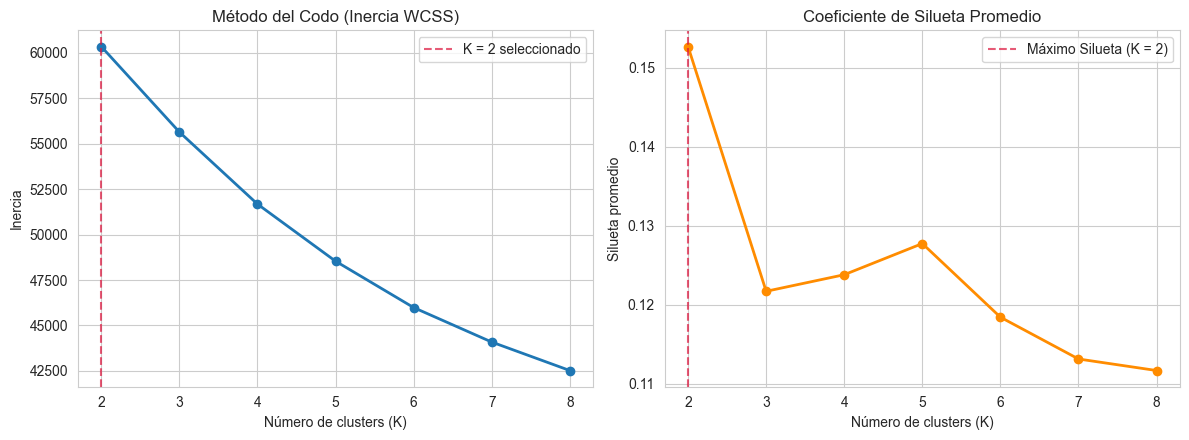

,K,Inercia,Silueta,Davies_Bouldin
0,2,60351.9,0.1527,2.2973
1,3,55646.5,0.1217,2.3404
2,4,51679.2,0.1238,2.1166
3,5,48535.4,0.1277,2.0874
4,6,45982.1,0.1184,2.0679
5,7,44082.7,0.1131,1.9474
6,8,42515.1,0.1116,1.9116


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(list(K_range), inertias, marker='o', color='#1f77b4', linewidth=2)
axes[0].axvline(2, color='crimson', linestyle='--', alpha=0.7, label='K = 2 seleccionado')
axes[0].set_title('Método del Codo (Inercia WCSS)')
axes[0].set_xlabel('Número de clusters (K)')
axes[0].set_ylabel('Inercia')
axes[0].legend()

axes[1].plot(list(K_range), silhouettes, marker='o', color='darkorange', linewidth=2)
axes[1].axvline(2, color='crimson', linestyle='--', alpha=0.7, label='Máximo Silueta (K = 2)')
axes[1].set_title('Coeficiente de Silueta Promedio')
axes[1].set_xlabel('Número de clusters (K)')
axes[1].set_ylabel('Silueta promedio')
axes[1].legend()
plt.tight_layout()
plt.show()

resumen_k = pd.DataFrame({
    'K': list(K_range),
    'Inercia': [round(i, 1) for i in inertias],
    'Silueta': [round(s, 4) for s in silhouettes],
    'Davies_Bouldin': [round(d, 4) for d in db_scores]
})
resumen_k

**Justificación de $K = 2$:**

- **Silueta:** $K = 2$ alcanza el máximo de todo el rango (`0.1527`); con $K = 3$ baja a `0.1217` y con $K = 4$ a `0.1238`.
- **Codo (inercia):** la curva baja de forma suave, sin un quiebre claro (de $K=2$ a $K=3$ la inercia se reduce 7,8 %, y de $K=3$ a $K=4$ otro 7,1 %), por lo que el método del codo no define un $K$ por sí solo.
- **Davies-Bouldin:** mejora (disminuye) casi de manera continua al aumentar $K$ y su mejor valor está en $K=8$ (`1.9116`), de modo que este criterio no coincide con la silueta.
- **Decisión:** se adopta $K=2$ por tener la mayor silueta y la partición más simple de interpretar.

> **Advertencia:** una silueta de `0.15` es baja (valores inferiores a 0,25 suelen interpretarse como ausencia de estructura sustancial). Los clientes bancarios se distribuyen de forma continua, sin grupos bien separados, por lo que los dos segmentos deben leerse como **tendencias de la cartera** y no como grupos naturales nítidos.


In [6]:
K_FINAL = 2
kmeans = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10)
df['cluster_kmeans'] = kmeans.fit_predict(X_clustering)

print('Distribución de clientes por cluster (K=2):')
print(df['cluster_kmeans'].value_counts().sort_index())

Distribución de clientes por cluster (K=2):
cluster_kmeans
0    5908
1    4092
Name: count, dtype: int64


## 5. Interpretación de los centroides

Cada centroide representa al "cliente prototípico" de su grupo. Primero se muestran en el **espacio estandarizado** (tal como los ve el algoritmo) y luego en **unidades originales de negocio** (años de edad, dólares de saldo, cantidad de productos y proporciones de cada categoría). Para las numéricas equivale a revertir el escalado con `inverse_transform` (el promedio por cluster en unidades originales coincide con el centroide revertido, salvo diferencias de décimas por la tolerancia de convergencia de K-Means); para las dummies y binarias el promedio es directamente la **proporción** de clientes del grupo en esa categoría.


In [7]:
columnas_transformadas = preprocess.get_feature_names_out()

centroids_scaled = kmeans.cluster_centers_
centroids_df = pd.DataFrame(centroids_scaled, columns=columnas_transformadas).round(2)
centroids_df.index.name = 'Cluster'
centroids_df

,num__CreditScore,num__Age,num__Tenure,num__Balance,num__NumOfProducts,num__EstimatedSalary,cat__Geography_Germany,cat__Geography_Spain,cat__Gender_Male,bin__HasCrCard,bin__IsActiveMember
Cluster,,,,,,,,,,,
0,0.01,0.02,-0.02,0.74,-0.40,0.01,0.39,0.20,0.55,0.70,0.52
1,-0.01,-0.03,0.02,-1.06,0.57,-0.02,0.05,0.32,0.53,0.71,0.51


In [8]:
# Centroides en unidades originales (promedio de cada variable por cluster)
n_num = len(num_cols)
grupos = df.groupby('cluster_kmeans')

centroides_num = grupos[num_cols].mean()

# dummies y binarias: su promedio por cluster es la proporción de clientes en esa categoría
otras = X_clustering.iloc[:, n_num:].copy()
otras.columns = [c.split('__')[1] for c in otras.columns]
otras['cluster_kmeans'] = df['cluster_kmeans'].values
centroides_otros = otras.groupby('cluster_kmeans').mean()

centroides_orig = pd.concat([centroides_num, centroides_otros], axis=1).round(2)
centroides_orig.index.name = 'Cluster'

# Proporción de clientes con saldo cero en cada cluster
centroides_orig['Balance_cero_%'] = grupos['Balance'].apply(lambda s: 100 * (s == 0).mean()).round(1)
centroides_orig.T


Cluster,0,1
CreditScore,651.35,649.34
Age,39.10,38.67
Tenure,4.97,5.08
Balance,122517.76,10025.40
NumOfProducts,1.30,1.86
EstimatedSalary,100790.74,99078.86
Geography_Germany,0.39,0.04
Geography_Spain,0.20,0.32
Gender_Male,0.55,0.53
HasCrCard,0.70,0.71


**Lectura de los centroides ($K=2$):**

Los dos grupos se diferencian sobre todo por el **saldo en cuenta**, la **cantidad de productos** y la **ubicación geográfica**. El resto de las variables (`CreditScore`, `Tenure`, `EstimatedSalary`, edad, género, tarjeta de crédito y actividad) casi no discrimina entre los grupos.

- **Cluster 0 (5.908 clientes, 59,1 % de la cartera) — con saldo y mayor presencia alemana:** saldo medio de $\approx$ USD 122.518 (ningún cliente tiene saldo cero), $1{,}30$ productos en promedio y un 39,4 % de clientes de **Alemania** (40,8 % Francia y 19,8 % España). Edad media de 39,1 años y 51,6 % de miembros activos.
- **Cluster 1 (4.092 clientes, 40,9 % de la cartera) — mayormente sin saldo:** saldo medio de $\approx$ USD 10.025, con un **88,4 % de clientes con saldo cero**, $1{,}86$ productos en promedio y predominio de **Francia** (63,6 %; Alemania solo 4,5 % y España 31,9 %). Edad media de 38,7 años y 51,4 % de miembros activos.

En síntesis, la segmentación separa principalmente a quienes **mantienen saldo en el banco** de quienes tienen **saldo cero o muy bajo**, con la geografía acompañando esa diferencia (en la base, ningún cliente de Alemania tiene saldo cero, frente a cerca del 48 % en Francia y en España).


## 6. PCA — Reducción a 2 dimensiones e interpretación de cargas (*loadings*)

Para visualizar un espacio de 11 variables proyectamos los datos sobre sus **2 primeras Componentes Principales (PCA)**, que son las combinaciones lineales ortogonales que retienen la mayor varianza posible.

Además de calcular el porcentaje de varianza explicada, inspeccionamos la **matriz de cargas (`pca.components_`)** para entender qué variables originales impulsan cada eje del gráfico.

In [9]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_clustering)

var_exp = pca.explained_variance_ratio_
print(f'Varianza explicada PC1: {var_exp[0]:.2%}')
print(f'Varianza explicada PC2: {var_exp[1]:.2%}')
print(f'Varianza explicada acumulada (2 componentes): {var_exp.sum():.2%}')

var_acum = np.cumsum(PCA(random_state=RANDOM_STATE).fit(X_clustering).explained_variance_ratio_)
print('Varianza acumulada con 1 a 11 componentes:', np.round(var_acum, 3))

loadings = pd.DataFrame(
    pca.components_.T,
    index=columnas_transformadas,
    columns=['PC1 (Cargas)', 'PC2 (Cargas)']
).round(3)
loadings.reindex(loadings['PC1 (Cargas)'].abs().sort_values(ascending=False).index)

Varianza explicada PC1: 18.76%
Varianza explicada PC2: 14.34%
Varianza explicada acumulada (2 componentes): 33.10%
Varianza acumulada con 1 a 11 componentes: [0.188 0.331 0.472 0.613 0.752 0.855 0.891 0.925 0.955 0.984 1.   ]


,PC1 (Cargas),PC2 (Cargas)
num__Balance,0.711,0.111
num__NumOfProducts,-0.677,-0.039
num__Age,0.134,-0.521
cat__Geography_Germany,0.116,0.015
num__Tenure,-0.059,0.581
cat__Geography_Spain,-0.045,-0.009
num__CreditScore,-0.013,0.088
cat__Gender_Male,0.008,0.012
bin__HasCrCard,-0.006,0.006
num__EstimatedSalary,-0.004,0.606


**Interpretación de las componentes principales:**

- Las dos primeras componentes capturan el **$33,10\,\%$ de la varianza total** ($18,76\,\%$ en PC1 y $14,34\,\%$ en PC2). Hacen falta **6 componentes** para superar el 85 % ($85,5\,\%$). Esto ocurre porque las variables bancarias (`CreditScore`, `Tenure`, `HasCrCard`, `EstimatedSalary`) son casi independientes entre sí y reparten la varianza de manera uniforme.
- **PC1** contrapone **`Balance`** (carga $+0,711$) frente a **`NumOfProducts`** ($-0,677$), con un aporte menor de `Age` y `Geography_Germany`. Es el eje que separa a los clientes **con saldo y pocos productos** de los que tienen **más productos y saldo cero**, y es exactamente la diferencia que usa K-Means: el valor medio de PC1 es $+0,81$ en el cluster 0 y $-1,17$ en el cluster 1.
- **PC2** combina **`EstimatedSalary`** ($+0,606$), **`Tenure`** ($+0,581$) y `Age` ($-0,521$). Son variables que casi no difieren entre los clusters, por lo que los dos grupos se **solapan a lo largo de PC2**.
- Las variables dummy y binarias tienen cargas muy pequeñas (menores a $0,12$ en valor absoluto) porque su varianza es menor que la de las numéricas estandarizadas.


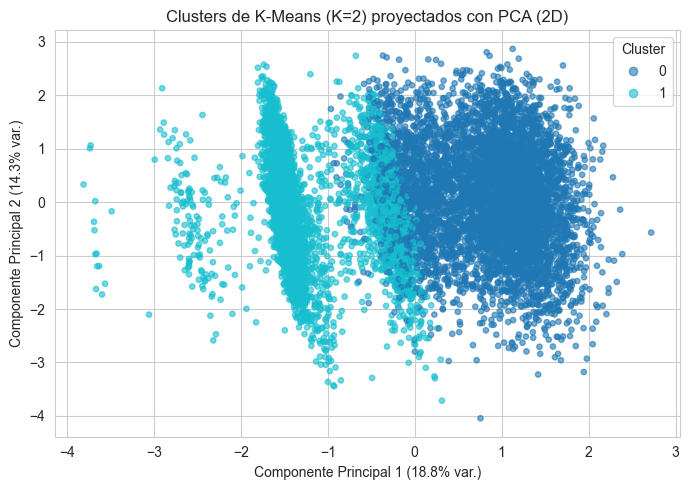

In [10]:
plt.figure(figsize=(7, 5))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster_kmeans'], cmap='tab10', alpha=0.6, s=15)
plt.xlabel(f'Componente Principal 1 ({var_exp[0]:.1%} var.)')
plt.ylabel(f'Componente Principal 2 ({var_exp[1]:.1%} var.)')
plt.title('Clusters de K-Means (K=2) proyectados con PCA (2D)')
plt.legend(*scatter.legend_elements(), title='Cluster')
plt.tight_layout()
plt.show()

## 7. DBSCAN — Selección de `eps` mediante $k$-NN y detección de *outliers*

A diferencia de K-Means, que obliga a todos los clientes a pertenecer a un grupo esférico, **DBSCAN** agrupa regiones de alta densidad y etiqueta como **ruido u *outliers* (`-1`)** a los clientes aislados.

Para no elegir el radio `eps` a ciegas, aplicamos la heurística de las **distancias al $k$-ésimo vecino más cercano (`NearestNeighbors`)** con `min_samples = 22` ($= 2 \times \text{dimensiones}$): ordenamos la distancia de cada cliente a su vecino $k=22$ y buscamos el **codo de máxima curvatura**, que distingue las zonas densas de los puntos atípicos.


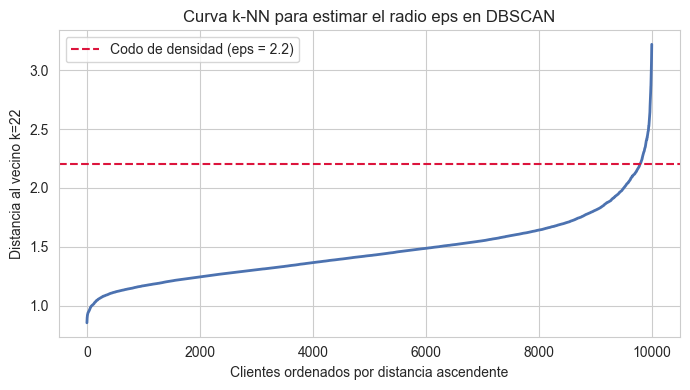

In [11]:
min_samples_db = 2 * X_clustering.shape[1]  # 22 vecinos
vecinos = NearestNeighbors(n_neighbors=min_samples_db)
vecinos.fit(X_clustering)
distancias, _ = vecinos.kneighbors(X_clustering)
distancias_ordenadas = np.sort(distancias[:, -1])

plt.figure(figsize=(7, 4))
plt.plot(distancias_ordenadas, color='#4C72B0', linewidth=2)
plt.axhline(y=2.2, color='crimson', linestyle='--', label='Codo de densidad (eps = 2.2)')
plt.xlabel('Clientes ordenados por distancia ascendente')
plt.ylabel(f'Distancia al vecino k={min_samples_db}')
plt.title('Curva k-NN para estimar el radio eps en DBSCAN')
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
dbscan = DBSCAN(eps=2.2, min_samples=min_samples_db)
df['cluster_dbscan'] = dbscan.fit_predict(X_clustering)

n_clusters_db = len(set(df['cluster_dbscan'])) - (1 if -1 in df['cluster_dbscan'].values else 0)
n_outliers = (df['cluster_dbscan'] == -1).sum()
print(f'Clusters densos detectados por DBSCAN: {n_clusters_db}')
print(f'Outliers detectados (-1): {n_outliers} ({n_outliers/len(df):.1%} del total)')
print('\nConteo por etiqueta de DBSCAN:')
print(df['cluster_dbscan'].value_counts().sort_index())

Clusters densos detectados por DBSCAN: 1
Outliers detectados (-1): 37 (0.4% del total)

Conteo por etiqueta de DBSCAN:
cluster_dbscan
-1      37
 0    9963
Name: count, dtype: int64


In [13]:
# Sensibilidad de DBSCAN al radio eps (con min_samples fijo)
filas = []
for eps in [1.5, 1.8, 2.0, 2.2, 2.5, 3.0]:
    etiquetas = DBSCAN(eps=eps, min_samples=min_samples_db).fit_predict(X_clustering)
    filas.append({
        'eps': eps,
        'clusters': len(set(etiquetas)) - (1 if -1 in etiquetas else 0),
        'outliers (-1)': int((etiquetas == -1).sum()),
        'outliers (%)': round(100 * (etiquetas == -1).mean(), 1),
    })
print(pd.DataFrame(filas).to_string(index=False))

# Perfil de los outliers detectados con eps = 2.2
out = df[df['cluster_dbscan'] == -1]
print(f"\nOutliers con eps=2.2: {len(out)} clientes")
print(f"Edad media: {out['Age'].mean():.1f} | Balance medio: {out['Balance'].mean():,.0f} | Productos medios: {out['NumOfProducts'].mean():.1f}")
print(f"Clientes con 4 productos: {(out['NumOfProducts'] == 4).sum()} de {len(out)}")
print(f"Tasa de churn entre los outliers: {out['Exited'].mean():.1%} (global: {df['Exited'].mean():.1%})")


 eps  clusters  outliers (-1)  outliers (%)
 1.5         2           1028          10.3
 1.8         1            337           3.4
 2.0         1             94           0.9
 2.2         1             37           0.4
 2.5         1              1           0.0
 3.0         1              0           0.0

Outliers con eps=2.2: 37 clientes
Edad media: 49.9 | Balance medio: 109,495 | Productos medios: 3.7
Clientes con 4 productos: 31 de 37
Tasa de churn entre los outliers: 94.6% (global: 20.4%)


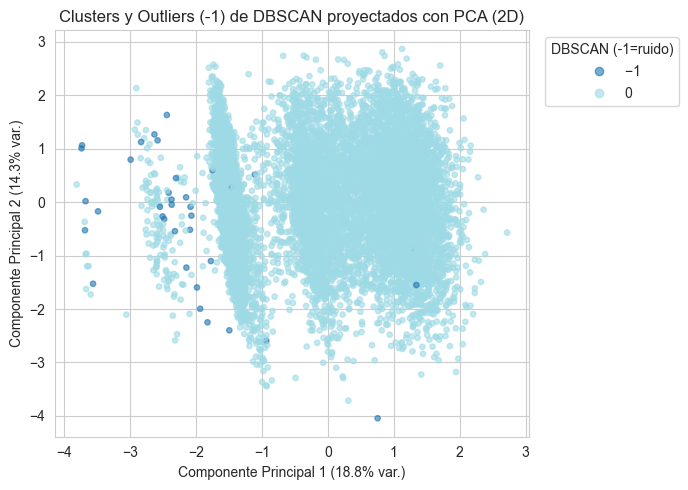

In [14]:
plt.figure(figsize=(7, 5))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster_dbscan'], cmap='tab20', alpha=0.6, s=15)
plt.xlabel(f'Componente Principal 1 ({var_exp[0]:.1%} var.)')
plt.ylabel(f'Componente Principal 2 ({var_exp[1]:.1%} var.)')
plt.title('Clusters y Outliers (-1) de DBSCAN proyectados con PCA (2D)')
plt.legend(*scatter.legend_elements(), title='DBSCAN (-1=ruido)', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Comparación K-Means vs. DBSCAN:**
- Con `eps = 2.2`, DBSCAN encuentra **un único grupo denso** (9.963 clientes) y marca como ruido a **37 clientes (0,4 %)**. La curva $k$-NN no muestra un codo nítido (sube de forma gradual y se dispara recién en el último 2 % de los clientes), por lo que el resultado es sensible a `eps`: con `eps = 2.0` hay 94 outliers y con `eps = 2.5` solo 1 (ver tabla). Es decir, no halla subgrupos densos separados: es coherente con la silueta baja de K-Means, que indicaba que la cartera no tiene grupos nítidos. Con un radio menor (`eps = 1.5`) aparecen 2 grupos, pero a costa de dejar más del 10 % de la cartera como ruido, y con radios mayores el resultado vuelve a ser un solo grupo.
- Los **outliers** son principalmente clientes con **4 productos** (31 de los 37), de mayor edad (49,9 años en promedio), y el **94,6 %** de ellos abandonó el banco. Esto coincide con lo visto en el Avance 1: abandonan el 100 % de los clientes con 4 productos.
- Para **segmentar toda la cartera** en grupos exhaustivos para marketing y retención usamos **K-Means ($K=2$)**, mientras que **DBSCAN** aporta valor complementario como detector de perfiles anómalos para revisión individual.


## 8. t-SNE — Visualización no lineal en 2D

Mientras que PCA busca proyecciones lineales que maximicen la varianza global, **t-SNE** preserva las vecindades locales de forma *no lineal*: clientes muy parecidos en las 11 dimensiones quedan juntos en el mapa 2D. Esto permite inspeccionar subestructuras internas dentro de cada uno de los 2 clusters de K-Means. Conviene recordar que en t-SNE las distancias entre grupos y el tamaño de las nubes no tienen una interpretación directa, por lo que se usa solo como apoyo visual.

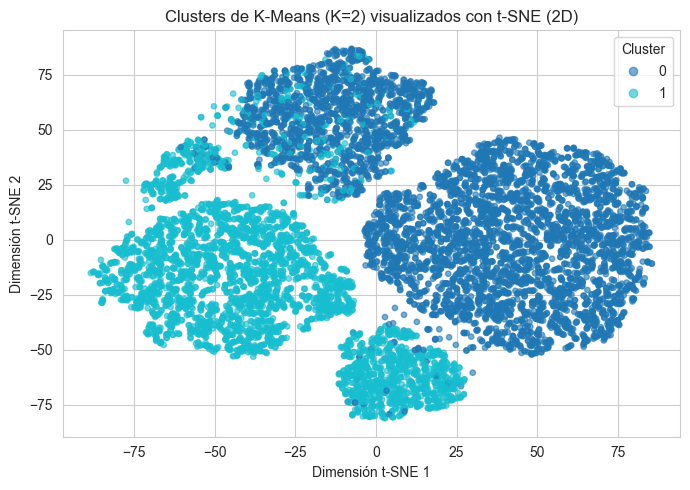

In [15]:
tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30, init='pca')
X_tsne = tsne.fit_transform(X_clustering)

plt.figure(figsize=(7, 5))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=df['cluster_kmeans'], cmap='tab10', alpha=0.6, s=15)
plt.xlabel('Dimensión t-SNE 1')
plt.ylabel('Dimensión t-SNE 2')
plt.title('Clusters de K-Means (K=2) visualizados con t-SNE (2D)')
plt.legend(*scatter.legend_elements(), title='Cluster')
plt.tight_layout()
plt.show()

## 9. Evaluación *ex-post* frente al *Churn* y creación de *features*

Recién ahora incorporamos `Exited` para evaluar si los 2 segmentos descubiertos sin supervisión exhiben comportamientos diferenciados de abandono. Además, calculamos la tasa de *churn* del segmento (`cluster_churn_rate`) como ejemplo de *feature* derivada (teniendo presente que en un flujo supervisado productivo debe ajustarse solo sobre `train` para evitar *data leakage*).

In [16]:
churn_global = df['Exited'].mean()
print(f'Tasa de churn global del banco: {churn_global:.2%}')

resumen = df.groupby('cluster_kmeans').agg(
    clientes=('Exited', 'size'),
    porcentaje_cartera=('Exited', lambda s: round(100 * len(s) / len(df), 1)),
    tasa_churn_pct=('Exited', lambda s: round(100 * s.mean(), 2)),
    edad_media=('Age', 'mean'),
    balance_medio=('Balance', 'mean'),
    productos_medio=('NumOfProducts', 'mean'),
    activos_pct=('IsActiveMember', lambda s: round(100 * s.mean(), 1)),
    # --- Nuevas variables categóricas (% por categoría) ---
    mujeres_pct=('Gender', lambda s: round(100 * (s == 'Female').mean(), 1)),
    
    # Si sabes los países exactos (ej. France, Germany, Spain), puedes medirlos así:
    francia_pct=('Geography', lambda s: round(100 * (s == 'France').mean(), 1)),
    alemania_pct=('Geography', lambda s: round(100 * (s == 'Germany').mean(), 1)),
    espana_pct=('Geography', lambda s: round(100 * (s == 'Spain').mean(), 1))
).round(2)

df['cluster_churn_rate'] = df.groupby('cluster_kmeans')['Exited'].transform('mean')
resumen.sort_values('tasa_churn_pct', ascending=False)

Tasa de churn global del banco: 20.37%


,clientes,porcentaje_cartera,tasa_churn_pct,edad_media,balance_medio,productos_medio,activos_pct,mujeres_pct,francia_pct,alemania_pct,espana_pct
cluster_kmeans,,,,,,,,,,,
0,5908,59.1,22.38,39.10,122517.76,1.30,51.6,44.6,40.8,39.4,19.8
1,4092,40.9,17.47,38.67,10025.40,1.86,51.4,46.6,63.6,4.5,31.9


In [17]:
# ¿La diferencia de churn entre los dos clusters es estadísticamente significativa? (chi-cuadrado)
from scipy.stats import chi2_contingency

tabla_contingencia = pd.crosstab(df['cluster_kmeans'], df['Exited'])
chi2, p_valor, _, _ = chi2_contingency(tabla_contingencia)
dif_pp = resumen.loc[0, 'tasa_churn_pct'] - resumen.loc[1, 'tasa_churn_pct']
print(f"Churn cluster 0: {resumen.loc[0, 'tasa_churn_pct']:.2f}% | cluster 1: {resumen.loc[1, 'tasa_churn_pct']:.2f}% | diferencia: {dif_pp:.2f} puntos porcentuales")
print(f"Chi-cuadrado = {chi2:.1f} | p-valor = {p_valor:.1e}")


Churn cluster 0: 22.38% | cluster 1: 17.47% | diferencia: 4.91 puntos porcentuales
Chi-cuadrado = 35.5 | p-valor = 2.5e-09


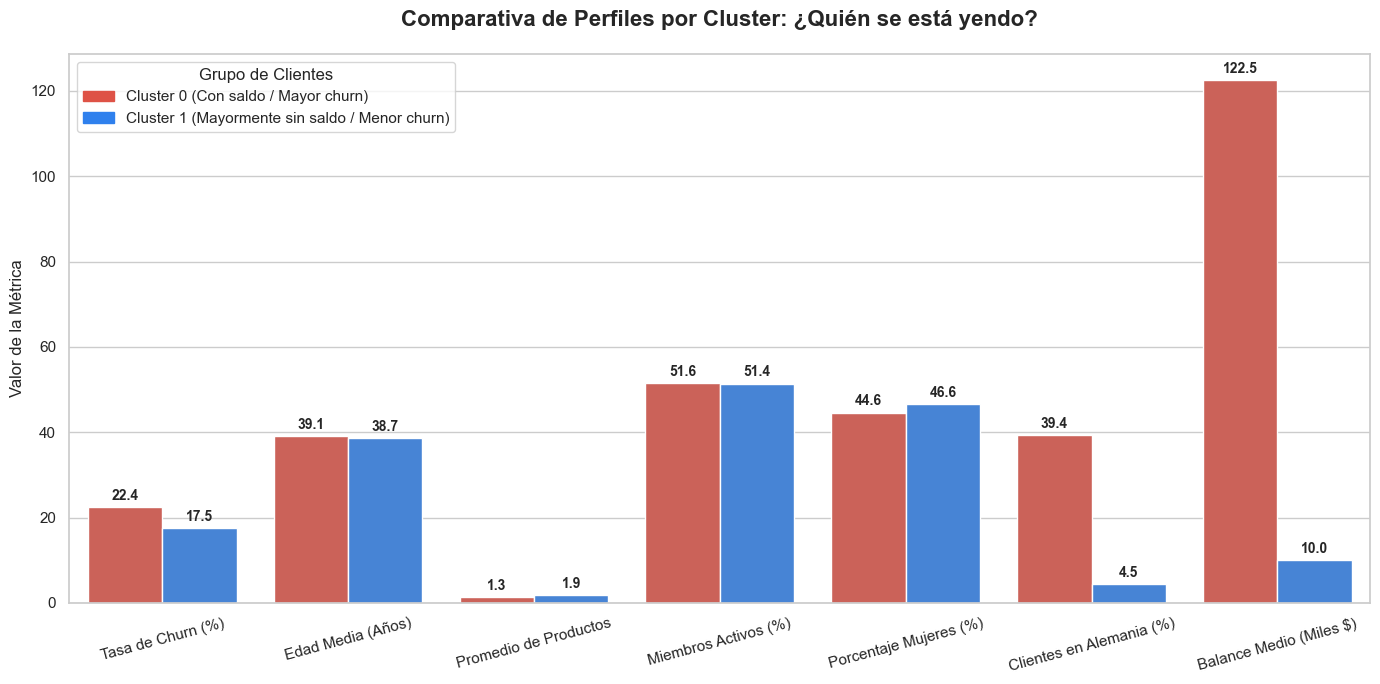

In [18]:
# 1. Seleccionamos las variables clave que queremos comparar (convertimos porcentajes a escala 0-100)
columnas_grafico = {
    'tasa_churn_pct': 'Tasa de Churn (%)',
    'edad_media': 'Edad Media (Años)',
    'productos_medio': 'Promedio de Productos',
    'activos_pct': 'Miembros Activos (%)',
    'mujeres_pct': 'Porcentaje Mujeres (%)',
    'alemania_pct': 'Clientes en Alemania (%)'
}

# Creamos una copia del resumen con nombres amigables
df_plot = resumen[list(columnas_grafico.keys())].rename(columns=columnas_grafico)

# Añadimos el Balance Medio dividido por 1,000 para que no rompa la escala del gráfico
df_plot['Balance Medio (Miles $)'] = resumen['balance_medio'] / 1000

# 2. Transponemos el DataFrame para que sea fácil de graficar con Seaborn
df_melted = df_plot.reset_index().melt(id_vars='cluster_kmeans', var_name='Métrica', value_name='Valor')

# 3. Configuramos el diseño del gráfico
plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

# Creamos el gráfico de barras
ax = sns.barplot(
    data=df_melted, 
    x='Métrica', 
    y='Valor', 
    hue='cluster_kmeans', 
    palette=['#DE5246', '#2F80ED']  # Rojo para el crítico, Azul para el estable
)

# 4. Personalización estética ejecutiva
plt.title('Comparativa de Perfiles por Cluster: ¿Quién se está yendo?', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('', fontsize=12)
plt.ylabel('Valor de la Métrica', fontsize=12)
plt.xticks(rotation=15, fontsize=11)
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color='#DE5246', label='Cluster 0 (Con saldo / Mayor churn)'),
                    Patch(color='#2F80ED', label='Cluster 1 (Mayormente sin saldo / Menor churn)')],
           title='Grupo de Clientes', fontsize=11)

# Añadir los valores numéricos arriba de cada barra para facilitar la lectura
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.1f}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', 
                    xytext=(0, 8), 
                    textcoords='offset points', 
                    fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

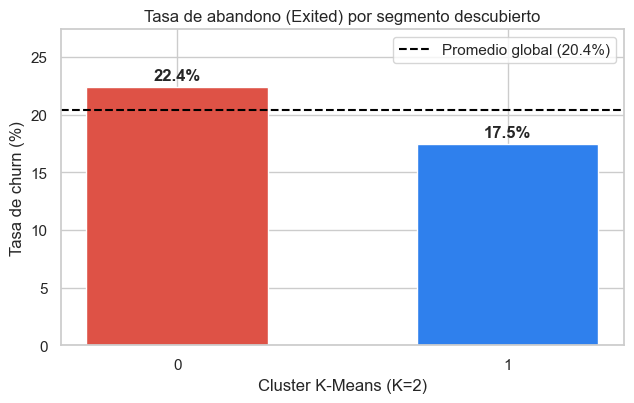

In [19]:
plt.figure(figsize=(6.5, 4.2))
bars = plt.bar(resumen.index.astype(str), resumen['tasa_churn_pct'], color=['#DE5246', '#2F80ED'], width=0.55)
plt.axhline(churn_global * 100, color='black', linestyle='--', label=f'Promedio global ({churn_global:.1%})')
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 0.6, f'{h:.1f}%', ha='center', fontweight='bold')
plt.ylim(0, max(resumen['tasa_churn_pct']) + 5)
plt.xlabel('Cluster K-Means (K=2)')
plt.ylabel('Tasa de churn (%)')
plt.title('Tasa de abandono (Exited) por segmento descubierto')
plt.legend()
plt.tight_layout()
plt.show()

## 10. Conclusión — Perfiles de segmento y relación con el *churn*

A partir del análisis no supervisado sobre los 10.000 clientes de FinanceGuard concluimos:

1. **Elección de $K = 2$:** el coeficiente de silueta alcanza su máximo en $K=2$ (`0.1527`; con $K=3$ baja a `0.1217`). El método del codo no muestra un quiebre claro y el índice de Davies-Bouldin mejora al aumentar $K$, por lo que la decisión se apoya en la silueta y en la simplicidad. La silueta es baja: la cartera **no tiene grupos naturales nítidos** y los dos segmentos son tendencias, no grupos separados.
   - **Cluster 0 — Con saldo / mayor presencia alemana ($59,1\,\%$ de la cartera, *churn* del $22,4\,\%$):** saldo medio de $\approx$ USD 122.518, $1{,}30$ productos, $39,4\,\%$ de clientes de Alemania y $51,6\,\%$ de miembros activos.
   - **Cluster 1 — Mayormente sin saldo ($40,9\,\%$ de la cartera, *churn* del $17,5\,\%$):** saldo medio de $\approx$ USD 10.025 (el $88,4\,\%$ tiene saldo cero), $1{,}86$ productos, predominio de Francia ($63,6\,\%$) y $51,4\,\%$ de miembros activos.
   - La tasa de abandono global es del $20,4\,\%$. La diferencia entre clusters ($4,9$ puntos porcentuales) es **estadísticamente significativa** ($\chi^2 = 35{,}5$; $p \approx 2{,}5 \times 10^{-9}$) pero **moderada**: el segmento con saldo abandona más, sin que ninguno de los dos grupos sea de riesgo extremo.
2. **Aporte de PCA, t-SNE y DBSCAN:**
   - **PCA:** las dos primeras componentes capturan el $33,1\,\%$ de la varianza (hacen falta 6 para superar el 85 %). PC1 contrapone `Balance` frente a `NumOfProducts` y es el eje en el que se separan los dos clusters.
   - **t-SNE** se usó como apoyo visual de la estructura local.
   - **DBSCAN** (`eps = 2.2`, calibrado con la curva $k$-NN) encontró un único grupo denso y **37 clientes atípicos (0,4 %)**, casi todos con 4 productos (31 de 37), de los cuales abandonó el 94,6 %. No halla subgrupos densos separados, en línea con la silueta baja.
3. **Interpretación responsable:** pertenecer a un cluster describe un perfil asociado a mayor o menor riesgo, pero no implica causalidad. Los segmentos se explican por `Balance`, `NumOfProducts` y `Geography`, las mismas variables que ya dominaban los modelos supervisados de los Avances 1 y 2, por lo que **aportan una descripción de la cartera más que información nueva para predecir**. Como parte de la segmentación refleja el país de residencia, conviene evitar que se traduzca en un trato diferencial a los clientes por su nacionalidad. La variable derivada `cluster_churn_rate` solo debería usarse en un flujo supervisado si se calcula únicamente con los datos de `train`.
